# 002 YOLO11s comparison (Member 3)

Research notebook for the comparison model and the Stage 4 progress check. YOLO11s uses the same training implementation as YOLO11n. All threshold selection uses the frozen 73-image validation split; the subsequent held-out test evaluation is recorded in `reports/results_checkpoint/`.

The original Stage 3 report is preserved in `planning/intro_to_cv_3.pdf`. Its YOLO11s checkpoints were not retained. New runs are documented as a reproduction attempt, rather than replacing the historical reported numbers.


In [1]:
import json
import platform
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import ultralytics
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'scripts/train_yolo11s.py').exists())
print('python:', platform.python_version())
print('torch:', torch.__version__, '| ultralytics:', ultralytics.__version__)
print('mps:', torch.backends.mps.is_available(), '| cuda:', torch.cuda.is_available())


python: 3.14.7
torch: 2.14.1 | ultralytics: 8.4.175
mps: True | cuda: False


## Dataset and shared protocol

All 11 Construction-PPE classes are retained. Split sizes are 1265 / 73 / 78. The shared protocol is 50 epochs, batch 16, input 640, SGD lr0=0.01, momentum=0.937, weight decay=0.0005, three warmup epochs, and cosine decay. Horizontal flips and mild geometric/HSV jitter are enabled; mosaic, mixup and copy-paste are off. Seeds are 42, 43 and 44.


In [2]:
manifest = pd.read_csv(ROOT / 'reports/dataset/split_manifest.csv')
print(manifest.groupby('split').size().to_dict())
assert manifest.groupby('split').size().to_dict() == {'test': 78, 'train': 1265, 'val': 73}
assert manifest.groupby('group')['split'].nunique().max() == 1
display(pd.read_csv(ROOT / 'reports/dataset/class_counts.csv').query("split != 'all'").pivot(index='class_name', columns='split', values='boxes'))


{'test': 78, 'train': 1265, 'val': 73}


split,test,train,val
class_name,,,
Person,198,1884,162
boots,144,1413,40
gloves,57,1351,37
goggles,9,501,8
helmet,161,1454,119
no_boots,23,88,4
no_gloves,58,442,56
no_goggle,33,337,41
no_helmet,40,400,45


## Optional smoke run

Set `SMOKE_RUN=True` only to test a new environment. Its outputs go to an ignored scratch directory and never replace the full runs.


In [3]:
SMOKE_RUN = False
if SMOKE_RUN:
    subprocess.run([sys.executable, str(ROOT / 'scripts/train_yolo11s.py'), '--seeds', '42',
                    '--epochs', '2', '--project', 'reports/training/smoke'], cwd=ROOT, check=True)


## Full three-seed training

Set `FULL_RUN=True` to train into an unused destination, or run `python scripts/train_yolo11s.py --project reports/training/new_experiment` from the repository root. Existing completed runs are protected from overwriting. Training may take several hours. The recorded clean reproduction used `--jobs 3` on M2 Max.

Native MPS sparse-indexing attempts were interrupted and archived. Canonical runs start fresh from pretrained weights, with the original 50-epoch budget. The original detection criterion runs on CPU with differentiable device copies; model forward/backward remain on GPU. CPU NMS and metric bookkeeping avoid the observed MPS indexing faults. Tests compare loss values and prediction gradients at the real 8400-anchor, 11-class head shape. See `reports/training/reproduction_notes.md`.


In [4]:
FULL_RUN = False
if FULL_RUN:
    subprocess.run([sys.executable, str(ROOT / 'scripts/train_yolo11s.py')], cwd=ROOT, check=True)


## Saved training results


In [5]:
summary_path = ROOT / 'reports/training/yolo11s_summary.json'
assert summary_path.exists(), 'Train YOLO11s first; missing results must not be substituted with the old PDF table.'
summary = json.loads(summary_path.read_text())
print('device:', summary['device'], '| versions:', summary['versions'])
print('Training jobs:', summary.get('training_jobs', 1))
print('Loss backend:', sorted({r.get('training_loss_backend', 'native') for r in summary['runs']}))
print('Validation backend:', sorted({r.get('validation_backend', 'native') for r in summary['runs']}))
runs = pd.DataFrame([{'seed': r['seed'], 'train_s': r['train_seconds'], **r['metrics']} for r in summary['runs']])
display(runs[['seed', 'train_s', 'mAP50-95', 'mAP50', 'precision', 'recall']])
display(pd.DataFrame(summary['aggregate']).T)
display(pd.DataFrame(summary['runs'][0]['metrics']['per_class']).set_index('Class'))


device: mps | versions: {'python': '3.14.7', 'torch': '2.14.1', 'ultralytics': '8.4.175', 'platform': 'macOS-15.7.2-arm64-arm-64bit-Mach-O', 'hardware': 'Apple M2 Max'}
Training jobs: 3
Loss backend: ['cpu_detection_criterion_with_mps_model']
Validation backend: ['mps_forward_cpu_nms_and_metrics']


,seed,train_s,mAP50-95,mAP50,precision,recall
0,42,5336.7,0.2040,0.4850,0.6118,0.4524
1,43,5332.1,0.1931,0.4777,0.5420,0.4699
2,44,5326.1,0.2118,0.5225,0.5915,0.5153


,mean,std
mAP50-95,0.2030,0.0094
mAP50,0.4951,0.0240
precision,0.5818,0.0359
recall,0.4792,0.0325


,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP75,mAP50-95
Class,,,,,,,,
helmet,41.0,119.0,0.79496,0.74790,0.77071,0.79011,0.32800,0.37358
gloves,16.0,37.0,0.63023,0.48649,0.54911,0.50279,0.03908,0.16261
vest,42.0,92.0,0.71948,0.61957,0.66580,0.67590,0.31264,0.35277
boots,14.0,40.0,0.58952,0.25140,0.35249,0.38789,0.00903,0.12338
goggles,6.0,8.0,0.37421,0.37500,0.37461,0.36541,0.24500,0.19546
none,37.0,69.0,0.58704,0.59750,0.59222,0.58179,0.10515,0.22747
Person,72.0,162.0,0.81299,0.83333,0.82304,0.84480,0.39255,0.42675
no_helmet,27.0,45.0,0.40029,0.44500,0.42146,0.43546,0.03128,0.13366
no_goggle,25.0,41.0,0.38288,0.31707,0.34688,0.31801,0.03771,0.10344


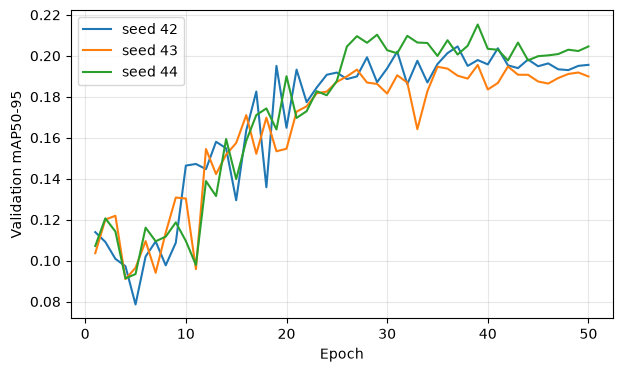

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for run in summary['runs']:
    curve = pd.read_csv(ROOT / run['run_dir'] / 'results.csv')
    ax.plot(curve['epoch'], curve['metrics/mAP50-95(B)'], label=f"seed {run['seed']}")
ax.set(xlabel='Epoch', ylabel='Validation mAP50-95')
ax.legend(); ax.grid(alpha=0.3)
plt.show()


## Common validation evaluation and threshold sensitivity

The evaluation script checks all six checkpoints, recomputes AP under a common environment, and sweeps confidence 0.05–0.90 in increments of 0.05. Matching is same-class, one-to-one at IoU >=0.50; NMS IoU is 0.70. Macro-F1 is the mean of class F1 scores, not the harmonic mean of macro precision/recall. One threshold per model maximizes mean macro-F1 across the three seeds; exact ties favour the lower threshold.

The optional latency benchmark uses the same device, FP32, batch one, confidence 0.25, warmup, and in-memory validation images for both models. It includes preprocessing, prediction, NMS, and predict-call overhead; disk IO and weight loading are excluded.

On MPS, NMS runs on CPU through the documented compatibility wrapper; both models use this path and timing includes transfers.


In [7]:
RUN_EVALUATION = False
if RUN_EVALUATION:
    subprocess.run([sys.executable, str(ROOT / 'scripts/evaluate_models.py'), '--benchmark'], cwd=ROOT, check=True)

validation = json.loads((ROOT / 'reports/evaluation/validation_summary.json').read_text())
assert validation['split'] == 'val' and not validation['test_used']
print('Selected confidence:', validation['selected_thresholds'])
display(pd.read_csv(ROOT / 'reports/evaluation/model_comparison.csv'))
print('Latency:', json.dumps(validation['latency'], indent=2))


Selected confidence: {'yolo11n': 0.2, 'yolo11s': 0.3}


,model,seeds,confidence,map50_95_mean,map50_95_std,map50_mean,map50_std,macro_precision_mean,macro_precision_std,macro_precision_ref025_mean,macro_precision_ref025_std,macro_recall_mean,macro_recall_std,macro_recall_ref025_mean,macro_recall_ref025_std,macro_f1_mean,macro_f1_std,macro_f1_ref025_mean,macro_f1_ref025_std
0,yolo11n,3,0.2,0.193848,0.011114,0.471612,0.029149,0.512769,0.055878,0.544759,0.043803,0.499821,0.014943,0.460818,0.022354,0.496201,0.025252,0.488212,0.026508
1,yolo11s,3,0.3,0.204262,0.008027,0.496617,0.011939,0.576675,0.015568,0.541355,0.012972,0.484019,0.019867,0.502270,0.028284,0.518175,0.015476,0.513187,0.015991


Latency: {
  "yolo11n": {
    "median_ms": 7.5771871488541365,
    "p25_ms": 7.016374729573727,
    "p75_ms": 8.689177338965237,
    "warmup": 20,
    "repeats": 100,
    "confidence": 0.25,
    "batch": 1,
    "precision": "FP32",
    "device": "mps",
    "includes": "predict-call overhead, resize/pad, model forward, NMS and result construction",
    "excludes": "disk IO, checkpoint loading, plotting"
  },
  "yolo11s": {
    "median_ms": 10.031291516497731,
    "p25_ms": 9.838676662184298,
    "p75_ms": 10.233437293209136,
    "warmup": 20,
    "repeats": 100,
    "confidence": 0.25,
    "batch": 1,
    "precision": "FP32",
    "device": "mps",
    "includes": "predict-call overhead, resize/pad, model forward, NMS and result construction",
    "excludes": "disk IO, checkpoint loading, plotting"
  }
}


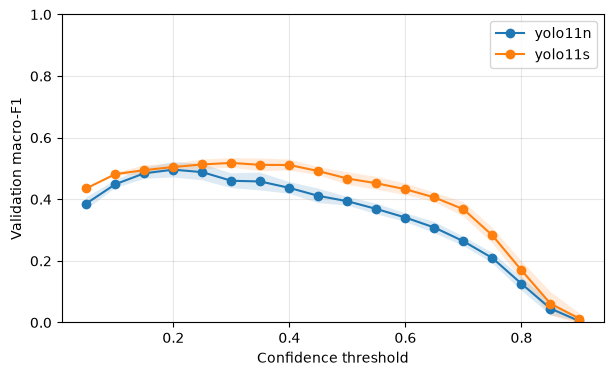

In [8]:
sweep = pd.read_csv(ROOT / 'reports/evaluation/confidence_summary.csv')
fig, ax = plt.subplots(figsize=(7, 4))
for name, group in sweep.groupby('model'):
    x = group['confidence'].to_numpy(); mean = group['mean'].to_numpy(); std = group['std'].fillna(0).to_numpy()
    ax.plot(x, mean, marker='o', label=name)
    ax.fill_between(x, mean-std, mean+std, alpha=0.15)
ax.set(xlabel='Confidence threshold', ylabel='Validation macro-F1', ylim=(0, 1))
ax.legend(); ax.grid(alpha=0.3)
plt.show()


## Historical results and completed test evaluation

Historical Stage 3 aggregates are stored separately in `reports/evaluation/stage3_reported.json` with their source and provenance. Never attach those numbers to the new checkpoints. Hardware and library versions can explain differences between runs.

The Results checkpoint completed held-out test metrics, size/visibility subgroup recall and three annotated failure cases using the frozen thresholds. See `reports/results_checkpoint/README.md` and the final PDF reports in `planning/`. Occlusion labels are a single assistant review; do not describe them as agreement between two human annotators.


In [9]:
historical = json.loads((ROOT / 'reports/evaluation/stage3_reported.json').read_text())
print(historical['provenance'])


Transcribed aggregate values from the submitted Stage 3 report. Original YOLO11s checkpoints and per-seed logs were not retained. These numbers are historical reported results, not measurements of the new checkpoints.
